# 01 · Data discovery

Before cleaning or modelling anything, this notebook establishes what the
data actually contains: which competitions and seasons, how much of
Barcelona's schedule is covered, what the event stream looks like, which
fields apply to which events, and how the two sources line up. It ends with
the **data coverage report** (`reports/data_coverage.md`) that the rest of the
project is scoped against.

| Source | What | Version |
|---|---|---|
| StatsBomb Open Data | events, lineups, 360 frames | commit `4b73468f` |
| football-data.co.uk | La Liga results, match stats, odds | SP1 1995/96 - 2020/21 |

Everything is read from `data/interim`, a lossless flattening of the raw
JSON/CSV produced by `barca interim`. Nothing is modified here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca import config, pipeline
from barca.data import normalize, sources
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

## 1. What StatsBomb publishes

The catalogue lists every competition-season in the open data. Only three
competitions contain Barcelona matches.

In [2]:
catalogue = pl.read_parquet(config.INTERIM / "catalogue.parquet").with_columns(
    ((pl.col("home_team") == "Barcelona") | (pl.col("away_team") == "Barcelona")).alias("barca")
)
(
    catalogue.group_by("competition")
    .agg(
        pl.col("season").n_unique().alias("seasons"),
        pl.col("season").min().alias("first"),
        pl.col("season").max().alias("last"),
        pl.len().alias("matches"),
        pl.col("barca").sum().alias("barcelona_matches"),
    )
    .sort("matches", descending=True)
)

competition,seasons,first,last,matches,barcelona_matches
str,u32,str,str,u32,u32
"""La Liga""",18,"""1973/1974""","""2020/2021""",867,525
"""Champions League""",18,"""1970/1971""","""2018/2019""",18,3
"""Copa del Rey""",3,"""1977/1978""","""1983/1984""",3,3


La Liga carries almost everything. The Champions League entries are finals
only (one match per season), and the Copa del Rey entries are three finals
from 1978-1984. Per season:

In [3]:
per_season = (
    catalogue.filter(pl.col("competition") == "La Liga")
    .group_by("season")
    .agg(pl.len().alias("matches"), pl.col("barca").sum().alias("barcelona"))
    .sort("season")
)
per_season

season,matches,barcelona
str,u32,u32
"""1973/1974""",1,1
"""2004/2005""",7,7
"""2005/2006""",17,17
"""2006/2007""",26,26
"""2007/2008""",27,27
"""2008/2009""",31,31
"""2009/2010""",35,35
"""2010/2011""",33,33
"""2011/2012""",37,37


Two things stand out:

* **2015/16 is complete** (380 matches). It is the only season with every
  club's every match, which makes it the reference season for league-wide
  event models (expected threat, rating baselines) and for opposition
  profiles.
* The other seasons contain **only Barcelona matches**, and the early ones
  only some of them. 1973/74 is a single, isolated match.

## 2. How much of Barcelona's league schedule is covered?

football-data.co.uk has every La Liga fixture, so it gives the denominator.

In [4]:
results = normalize.football_data_results(pl.read_parquet(config.INTERIM / "football_data.parquet"))
matches = normalize.matches(pl.read_parquet(config.INTERIM / "matches.parquet"))

barca_schedule = results.filter(
    ((pl.col("home") == "Barcelona") | (pl.col("away") == "Barcelona"))
    & pl.col("season_start").is_between(2004, 2020)
).with_columns(
    pl.when(pl.col("home") == "Barcelona").then(pl.col("home_goals")).otherwise(pl.col("away_goals")).alias("gf"),
    pl.when(pl.col("home") == "Barcelona").then(pl.col("away_goals")).otherwise(pl.col("home_goals")).alias("ga"),
)
covered_dates = matches.filter(pl.col("competition") == "La Liga", pl.col("is_barca")).select("date", "season")
barca_schedule = barca_schedule.join(
    covered_dates.with_columns(pl.lit(True).alias("covered")), on=["date", "season"], how="left"
).with_columns(
    pl.col("covered").fill_null(False),
    pl.when(pl.col("gf") > pl.col("ga")).then(3).when(pl.col("gf") == pl.col("ga")).then(1).otherwise(0).alias("points"),
)

coverage = (
    barca_schedule.group_by("season")
    .agg(
        pl.len().alias("league_matches"),
        pl.col("covered").sum().alias("covered"),
        pl.col("points").filter(pl.col("covered")).mean().round(2).alias("ppg_covered"),
        pl.col("points").filter(~pl.col("covered")).mean().round(2).alias("ppg_missing"),
    )
    .with_columns((pl.col("covered") / pl.col("league_matches")).round(3).alias("coverage"))
    .sort("season")
)
coverage

season,league_matches,covered,ppg_covered,ppg_missing,coverage
str,u32,u32,f64,f64,f64
"""2004/2005""",38,7,3.0,2.03,0.184
"""2005/2006""",38,17,2.71,1.71,0.447
"""2006/2007""",38,26,2.04,1.92,0.684
"""2007/2008""",38,27,1.93,1.36,0.711
"""2008/2009""",38,31,2.45,1.57,0.816
"""2009/2010""",38,35,2.63,2.33,0.921
"""2010/2011""",38,33,2.52,2.6,0.868
"""2011/2012""",38,37,2.38,3.0,0.974
"""2012/2013""",38,32,2.56,3.0,0.842


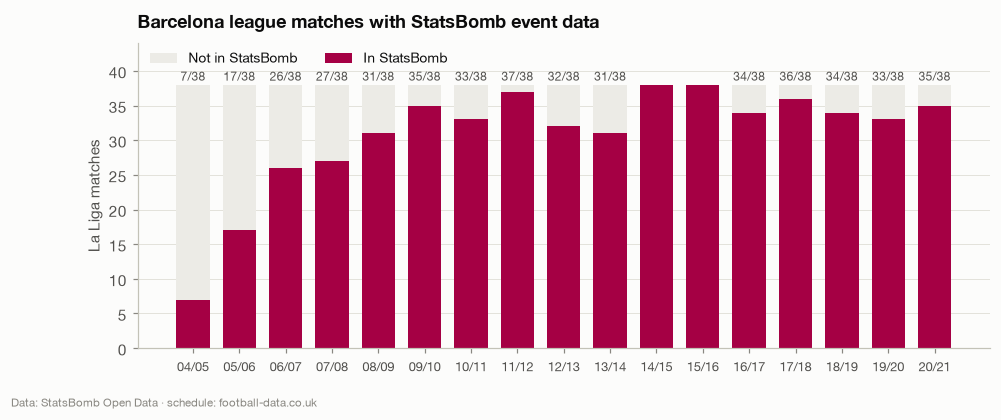

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
seasons = coverage["season"].str.slice(2, 2) + "/" + coverage["season"].str.slice(7, 2)
x = np.arange(coverage.height)
ax.bar(x, coverage["league_matches"], color="#ecebe6", width=0.72, label="Not in StatsBomb")
ax.bar(x, coverage["covered"], color=style.BARCA, width=0.72, label="In StatsBomb")
for xi, c, n in zip(x, coverage["covered"], coverage["league_matches"], strict=True):
    if c < n:
        ax.text(xi, n + 0.6, f"{c}/{n}", ha="center", fontsize=8, color=style.INK_2)
ax.set_xticks(x, seasons, fontsize=8.5)
ax.set_ylim(0, 44)
ax.set_ylabel("La Liga matches")
ax.set_title("Barcelona league matches with StatsBomb event data")
ax.legend(loc="upper left", ncols=2, bbox_to_anchor=(0, 1.02))
style.caption(ax, style.STATSBOMB_CREDIT + " · schedule: football-data.co.uk")
style.savefig(fig, "01_barca_coverage")
plt.show()

From 2008/09 onwards at least 31 of 38 league matches are covered each
season, and 2014/15 and 2015/16 are complete. The first four seasons are
thin: 7, 17, 26 and 27 matches.

**Is the missing part random?** StatsBomb assembled the historical seasons
around Lionel Messi's appearances, so matches he missed are the ones most
likely to be absent. If those matches were systematically worse for
Barcelona, any season-level average built from event data would be biased
upwards.

In [6]:
bias = barca_schedule.group_by("covered").agg(
    pl.len().alias("matches"),
    pl.col("points").mean().round(2).alias("points_per_game"),
    (pl.col("gf") - pl.col("ga")).mean().round(2).alias("goal_diff_per_game"),
)
bias

covered,matches,points_per_game,goal_diff_per_game
bool,u32,f64,f64
false,122,1.98,1.09
true,524,2.37,1.81


The covered matches have a higher points-per-game than the missing ones.
That is consistent with the Messi-centred selection: Barcelona did better
with him on the pitch. Consequences for the rest of the project:

1. **Team trends from event data are only reported for seasons with ≥80%
   coverage** (2008/09 onwards), and the early seasons are flagged.
2. **Results-based features (form, points, Elo) come from football-data**,
   which is complete, never from the StatsBomb subset.
3. Event-based rolling features are computed over the matches that exist
   and carry a coverage indicator, so a model can tell a thin window from a
   full one.

## 3. Opposition

Outside 2015/16, an opponent only appears when it plays Barcelona, usually
twice a season.

In [7]:
opp = (
    matches.filter(pl.col("is_barca"))
    .group_by("opponent")
    .agg(pl.len().alias("matches_vs_barca"), pl.col("season").n_unique().alias("seasons"))
    .sort("matches_vs_barca", descending=True)
)
print(f"{opp.height} different opponents")
opp.head(12)

42 different opponents


opponent,matches_vs_barca,seasons
str,u32,u32
"""Atlético Madrid""",30,16
"""Sevilla""",30,16
"""Real Madrid""",29,16
"""Valencia""",29,15
"""Espanyol""",27,16
"""Athletic Club""",27,16
"""Getafe""",25,16
"""Villarreal""",25,15
"""Real Sociedad""",23,12


In [8]:
non_barca_2015 = matches.filter(pl.col("season") == "2015/2016", ~pl.col("is_barca")).height
print(f"Matches not involving Barcelona: {non_barca_2015} (all in 2015/16)")

Matches not involving Barcelona: 342 (all in 2015/16)


So opponent *event* profiles exist in two forms: rich, full-season profiles
for the 20 clubs of 2015/16, and thin, Barcelona-only profiles for everyone
else. Opponent strength and form must therefore come from football-data and
Elo, with event-based opposition analysis limited to "how
does this opponent play *against Barcelona*".

## 4. Players and lineups

In [9]:
lineups = pl.read_parquet(config.INTERIM / "lineups.parquet").join(
    matches.select("match_id", "season", "date"), on="match_id"
)
barca_players = lineups.filter(pl.col("team") == "Barcelona")
print("Barcelona players (unique):", barca_players["player_id"].n_unique())
print("All players (unique):", lineups["player_id"].n_unique())

squads = (
    barca_players.group_by("season", "match_id")
    .agg(pl.len().alias("listed"), (pl.col("n_positions") == 0).sum().alias("unused_subs"))
    .group_by("season")
    .agg(
        pl.col("listed").mean().round(1).alias("players_listed_per_match"),
        (pl.col("unused_subs") > 0).mean().round(2).alias("share_with_unused_subs"),
    )
    .sort("season")
)
squads

Barcelona players (unique): 153
All players (unique): 2413


season,players_listed_per_match,share_with_unused_subs
str,f64,f64
"""2004/2005""",13.3,0.0
"""2005/2006""",14.3,0.12
"""2006/2007""",14.4,0.15
"""2007/2008""",15.4,0.41
"""2008/2009""",14.7,0.22
"""2009/2010""",14.4,0.17
"""2010/2011""",15.9,0.47
"""2011/2012""",14.1,0.05
"""2012/2013""",14.4,0.12


Lineups always list every player who appeared. The unused substitutes, and
with them the full matchday squad, are listed for **every match from 2015/16
onwards** but only sporadically before that (5-69% of matches per season).
That matters for the starting-XI model: Barcelona publishes its squad list
(*convocatoria*) the day before a match, so where the squad is recorded it is
legitimately known at prediction time and can serve as the candidate pool.
Where it is not, recent appearances are the fallback.

Players per season with at least one appearance:

In [10]:
(
    barca_players.filter(pl.col("n_positions") > 0)
    .group_by("season")
    .agg(pl.col("player_id").n_unique().alias("players_used"))
    .sort("season")
    .transpose(include_header=False, column_names="season")
)

2004/2005,2005/2006,2006/2007,2007/2008,2008/2009,2009/2010,2010/2011,2011/2012,2012/2013,2013/2014,2014/2015,2015/2016,2016/2017,2017/2018,2018/2019,2019/2020,2020/2021
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
21,21,21,26,21,23,25,29,23,24,25,25,25,25,26,27,25


There are no dates of birth in the open data, so age cannot be used as a
feature (the plan listed it as optional).

## 5. The event stream

In [11]:
events = pipeline.scan_events()
volume = (
    events.group_by("match_id")
    .agg(pl.len().alias("events"))
    .collect()
    .join(matches.select("match_id", "season"), on="match_id")
)
print("Total events:", f"{volume['events'].sum():,}")
volume.group_by("season").agg(
    pl.col("events").median().alias("median_events_per_match"),
    pl.col("events").min().alias("min"),
    pl.col("events").max().alias("max"),
).sort("season")

Total events: 3,140,830


season,median_events_per_match,min,max
str,f64,u32,u32
"""2004/2005""",3107.0,2770,3572
"""2005/2006""",3440.0,2770,3920
"""2006/2007""",3495.5,3152,4263
"""2007/2008""",3605.0,3240,3958
"""2008/2009""",3447.0,2716,3896
"""2009/2010""",3695.0,3123,4246
"""2010/2011""",3950.0,3372,4599
"""2011/2012""",3923.0,3370,4585
"""2012/2013""",4102.0,3348,4740


In [12]:
types = (
    events.group_by("type")
    .agg(pl.len().alias("events"), pl.col("match_id").n_unique().alias("matches"))
    .collect()
    .with_columns((pl.col("events") / pl.col("events").sum() * 100).round(2).alias("share_%"))
    .sort("events", descending=True)
)
types

type,events,matches,share_%
str,u32,u32,f64
"""Pass""",881588,869,28.07
"""Ball Receipt*""",816400,869,25.99
"""Carry""",706355,869,22.49
"""Pressure""",269980,869,8.6
"""Ball Recovery""",86321,869,2.75
"""Duel""",62169,869,1.98
"""Clearance""",36558,869,1.16
"""Dribble""",36221,869,1.15
"""Block""",30092,869,0.96


Pass, Ball Receipt and Carry make up about 77% of all events: most of a
football match is moving the ball between teammates. Pressure is the fourth
largest type. It is recorded for the pressing player, which makes it the
main defensive-intensity signal. Tackles do not have their own type: they
are `Duel` events with subtype `Tackle`.

## 6. Which fields apply to which events?

The flattened schema is wide (61 columns) and sparse by design. The matrix
below shows, per event type, the share of rows where each field is
populated. It is the reference for the data-quality rules in notebook 08: a
field that is ~100% populated for a type is an *expected* field, and a
missing value there is a defect. A field that is ~0% populated simply does
not apply.

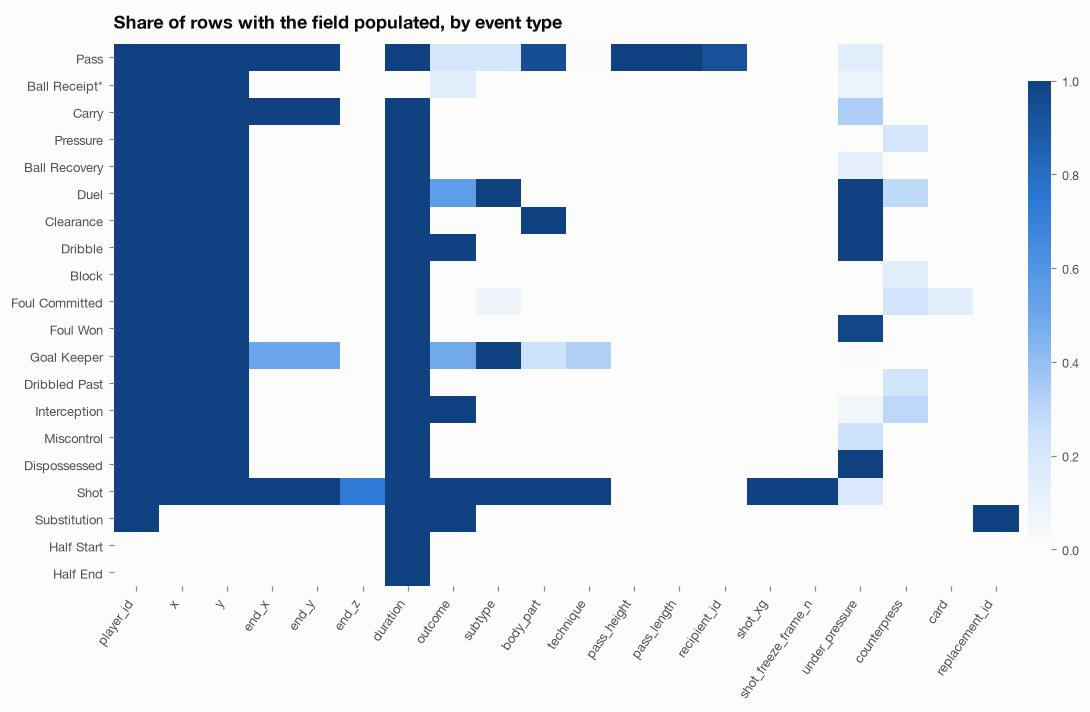

In [13]:
fields = [
    "player_id", "x", "y", "end_x", "end_y", "end_z", "duration", "outcome", "subtype",
    "body_part", "technique", "pass_height", "pass_length", "recipient_id", "shot_xg",
    "shot_freeze_frame_n", "under_pressure", "counterpress", "card", "replacement_id",
]
top_types = types["type"].head(20).to_list()
fill = (
    events.filter(pl.col("type").is_in(top_types))
    .group_by("type")
    .agg([pl.col(f).is_not_null().mean().alias(f) for f in fields])
    .collect()
)
fill = fill.join(types.select("type", "events"), on="type").sort("events", descending=True).drop("events")

fig, ax = plt.subplots(figsize=(11, 6.4))
mat = fill.drop("type").to_numpy()
im = ax.imshow(mat, cmap=style.HEAT_BLUE, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(fields)), fields, rotation=55, ha="right", fontsize=8.5)
ax.set_yticks(range(fill.height), fill["type"].to_list(), fontsize=8.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Share of rows with the field populated, by event type")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8)
style.savefig(fig, "01_field_matrix")
plt.show()

What the matrix tells us, and where it leads:

* `outcome` on **Pass** is only populated for unsuccessful passes. A null
  outcome means *complete*, the StatsBomb convention, so pass outcomes must
  never be imputed or dropped.
* **Shot** has xG, end location and a freeze frame on every row. A shot
  without xG would be a real defect.
* `end_z` exists only for shots (height at the goal line).
* `under_pressure` and `counterpress` are *flags*: null means false.
* Half Start/End, Starting XI and similar administrative events have no
  location. That is correct, not missing.

This is why the project never uses a blanket `dropna()`: it would delete
every completed pass.

## 7. Coordinate system

StatsBomb uses a 120 × 80 pitch with the origin at the top-left. Every event
is recorded from the perspective of the team performing it, attacking left
to right. Checks: ranges, and whether shots really cluster at high x.

In [14]:
coords = events.select(
    pl.col("x").min().alias("x_min"), pl.col("x").max().alias("x_max"),
    pl.col("y").min().alias("y_min"), pl.col("y").max().alias("y_max"),
    pl.col("end_x").min().alias("end_x_min"), pl.col("end_x").max().alias("end_x_max"),
    pl.col("end_y").min().alias("end_y_min"), pl.col("end_y").max().alias("end_y_max"),
    ((pl.col("x") > 120) | (pl.col("y") > 80) | (pl.col("x") < 0) | (pl.col("y") < 0)).sum().alias("outside_pitch"),
).collect()
coords

x_min,x_max,y_min,y_max,end_x_min,end_x_max,end_y_min,end_y_max,outside_pitch
f32,f32,f32,f32,f32,f32,f32,f32,u32
0.1,120.900002,0.1,80.800003,0.1,120.900002,0.1,80.900002,325


In [15]:
shots = events.filter(pl.col("type") == "Shot").select("x", "y", "shot_xg", "team").collect()
print("Shots taken from x > 60 (attacking half):", f"{(shots['x'] > 60).mean():.1%}")
print("Median shot distance to goal line (m):", round(float((120 - shots["x"]).median()), 1))

Shots taken from x > 60 (attacking half): 99.9%
Median shot distance to goal line (m): 14.7


Almost every shot comes from the attacking half, which confirms the
left-to-right convention. When both teams are drawn on one pitch, the
opponent's coordinates have to be mirrored (`x -> 120 - x`, `y -> 80 - y`).

A few hundred locations sit fractionally *outside* the frame, up to
120.9 × 80.9. They are touchline and by-line actions recorded a few
centimetres beyond the line, not corrupt values. They are clipped to the
pitch in cleaning, and the data-quality suite checks that nothing further
out appears.

## 8. StatsBomb 360

360 freeze frames exist for 2020/21 only: all 35 Barcelona matches.

In [16]:
ts = pl.read_parquet(config.INTERIM / "three_sixty.parquet")
per_match = ts.group_by("match_id").agg(
    pl.col("event_id").n_unique().alias("frames"), pl.len().alias("player_positions")
)
event_counts = volume.filter(pl.col("match_id").is_in(per_match["match_id"].implode()))
per_match = per_match.join(event_counts, on="match_id").with_columns(
    (pl.col("frames") / pl.col("events")).round(3).alias("share_of_events_with_frame"),
    (pl.col("player_positions") / pl.col("frames")).round(1).alias("players_visible_per_frame"),
)
per_match.select(
    pl.len().alias("matches"),
    pl.col("share_of_events_with_frame").mean().round(3),
    pl.col("players_visible_per_frame").mean().round(1),
)

matches,share_of_events_with_frame,players_visible_per_frame
u32,f64,f64
35,0.927,16.9


A 360 frame shows only the players visible in the broadcast shot, on
average about 17 of 22, and 93% of events have a frame. It is useful for spatial context (defensive shape
around the ball), but it only covers one season. No model depends on it. It is used in spatial EDA.

## 9. football-data.co.uk

Which fields exist in which seasons?

In [17]:
fd_fields = {
    "result": "home_goals",
    "half-time": "home_goals_ht",
    "shots": "home_shots",
    "shots on target": "home_sot",
    "corners": "home_corners",
    "cards": "home_yellow",
    "Bet365 odds": "odds_b365_h",
    "market-average odds": "odds_avg_h",
    "Pinnacle closing odds": "odds_psc_h",
}
fd_cov = (
    results.group_by("season")
    .agg([pl.col(c).is_not_null().mean().round(2).alias(k) for k, c in fd_fields.items()])
    .sort("season")
)
fd_cov

season,result,half-time,shots,shots on target,corners,cards,Bet365 odds,market-average odds,Pinnacle closing odds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""1995/1996""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""1996/1997""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""1997/1998""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""1998/1999""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""1999/2000""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2000/2001""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2001/2002""",1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2002/2003""",1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
"""2003/2004""",1.0,1.0,0.0,0.0,0.0,0.0,0.99,0.0,0.0


* Results and half-time scores exist for every season from 1995/96. Enough
  to run Elo from 1995 and let it settle before the first StatsBomb match.
* Shots, shots on target, corners and cards start in **2005/06**.
* Bet365 odds exist from 2002/03, so they cover the whole modelling window.
  Pinnacle *closing* odds, the sharpest public benchmark, start in 2012/13.
* 1995/96 and 1996/97 had 22 clubs (462 matches).

## 10. Do the two sources agree?

In [18]:
league = matches.filter(pl.col("competition") == "La Liga")
joined = league.join(
    results.select("date", "home", "away", "home_goals", "away_goals"),
    on=["date", "home", "away"],
    how="left",
)
agreement = joined.select(
    pl.len().alias("statsbomb_league_matches"),
    pl.col("home_goals").is_not_null().sum().alias("found_in_football_data"),
    ((pl.col("home_goals") == pl.col("home_score")) & (pl.col("away_goals") == pl.col("away_score")))
    .sum()
    .alias("same_score"),
)
agreement

statsbomb_league_matches,found_in_football_data,same_score
u32,u32,u32
866,866,866


After mapping team names through the crosswalk
(`src/barca/data/reference/teams.csv`), every StatsBomb league match is found
in football-data on the same date with the same score. The sources are
consistent, so they can be joined on `(date, home, away)`.

## 11. Coverage report

In [19]:
barca = matches.filter(pl.col("is_barca"))
report_rows = coverage.join(
    barca.group_by("season").agg(
        pl.col("barca_manager").unique().sort().str.join(" / ").alias("managers")
    ),
    on="season",
    how="left",
)
n_barca = barca.height
n_league_barca = barca.filter(pl.col("competition") == "La Liga").height

lines = [
    "# Data coverage report",
    "",
    "Generated by `notebooks/01_data_discovery.ipynb`. StatsBomb Open Data pinned at commit "
    f"`{sources.STATSBOMB_COMMIT[:8]}`; football-data.co.uk SP1 1995/96-2020/21.",
    "",
    "## Summary",
    "",
    "| Item | Value |",
    "|---|---|",
    f"| Matches with events | {matches.height} |",
    f"| Barcelona matches | {n_barca} ({n_league_barca} La Liga + {n_barca - n_league_barca} Champions League finals) |",
    f"| Complete league season | 2015/16 ({matches.filter(pl.col('season') == '2015/2016').height} matches) |",
    f"| Events | {volume['events'].sum():,} |",
    f"| Players (all teams) | {lineups['player_id'].n_unique():,} |",
    f"| Barcelona players | {barca_players['player_id'].n_unique()} |",
    f"| 360 matches | {per_match.height} (2020/21) |",
    f"| League results for Elo/form | {results.height:,} matches, 1995/96-2020/21 |",
    "",
    "## Barcelona league coverage by season",
    "",
    "| Season | Covered | Coverage | PPG covered | PPG missing | Manager(s) |",
    "|---|---|---|---|---|---|",
]
for r in report_rows.iter_rows(named=True):
    missing = "-" if r["ppg_missing"] is None else f"{r['ppg_missing']:.2f}"
    lines.append(
        f"| {r['season']} | {r['covered']}/{r['league_matches']} | {r['coverage']:.0%} | "
        f"{r['ppg_covered']:.2f} | {missing} | {r['managers']} |"
    )
lines += [
    "",
    "## Known gaps",
    "",
    "- 2004/05 to 2007/08 are partial and skewed towards matches Lionel Messi played; "
    "covered matches have a higher points-per-game than missing ones.",
    "- Outside 2015/16, opponents appear only in their matches against Barcelona.",
    "- No Champions League (other than three finals), Copa del Rey or Supercopa matches in the "
    "Barcelona era, so player workload only counts league minutes and those finals.",
    "- Full matchday squads (unused substitutes) are listed from 2015/16; before that only sporadically.",
    "- 325 event locations lie fractionally outside the 120 x 80 frame (max 120.9 x 80.9).",
    "- No player dates of birth.",
    "- football-data shots/corners/cards start in 2005/06; Pinnacle closing odds in 2012/13.",
    "- 360 freeze frames exist for 2020/21 only and show ~17 visible players per frame.",
]
(config.REPORTS / "data_coverage.md").write_text("\n".join(lines) + "\n")
print("\n".join(lines[:22]))

# Data coverage report

Generated by `notebooks/01_data_discovery.ipynb`. StatsBomb Open Data pinned at commit `4b73468f`; football-data.co.uk SP1 1995/96-2020/21.

## Summary

| Item | Value |
|---|---|
| Matches with events | 869 |
| Barcelona matches | 527 (524 La Liga + 3 Champions League finals) |
| Complete league season | 2015/16 (380 matches) |
| Events | 3,140,830 |
| Players (all teams) | 2,413 |
| Barcelona players | 153 |
| 360 matches | 35 (2020/21) |
| League results for Elo/form | 10,044 matches, 1995/96-2020/21 |

## Barcelona league coverage by season

| Season | Covered | Coverage | PPG covered | PPG missing | Manager(s) |
|---|---|---|---|---|---|
| 2004/2005 | 7/38 | 18% | 3.00 | 2.03 | Frank Rijkaard |


## Conclusions

1. **The core unit is a Barcelona league match, 2004/05-2020/21**, with
   reliable coverage from 2008/09. The complete 2015/16 season is the
   league-wide reference for event models.
2. **Early seasons are a biased sample** (Messi-centred). Event-based team
   trends are reported from 2008/09, and results-based features come from
   the complete football-data schedule.
3. **Opponent strength must come from football-data + Elo.** Opponent event
   profiles are only available against Barcelona (plus 2015/16).
4. **Workload will be underestimated.** Cup and European matches are missing.
   The workload index is therefore defined as *observed league workload* and
   documented as such.
5. **Missingness is structural, not random.** Pass outcomes, flags and
   administrative events are null by design, so validation must be
   event-type aware.
6. **Sources agree perfectly on results**, so joining on
   `(date, home, away)` is safe.

Next: match-level EDA (`02_match_eda`).